In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

from sklearn.naive_bayes import GaussianNB

# Read files

In [59]:
# trainingset
X_train = pd.read_csv("/Users/kellyt/Documents/ml/HW2/train1_icu_data.csv")
y_train = pd.read_csv("/Users/kellyt/Documents/ml/HW2/train1_icu_label.csv")

# testset
X_test = pd.read_csv("/Users/kellyt/Documents/ml/HW2/test1_icu_data.csv")
y_test = pd.read_csv("/Users/kellyt/Documents/ml/HW2/test1_icu_label.csv")

# Check dataset dimensions
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing features:", X_test.shape)
print("Testing labels:", y_test.shape)

# print("training distribution", y1_train.value_counts(normalize=True))
# print("testing distribution", y1_test.value_counts(normalize=True))
# A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().

# y_train = y_train.values.ravel()
# y_test = y_test.values.ravel()

Training features: (5000, 108)
Training labels: (5000, 1)
Testing features: (1097, 108)
Testing labels: (1097, 1)


# Build Naives Bayes Classifier Model


In [60]:
# Train GaussianNB
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Predict
y_pred = nb_model.predict(X_test)
y_prob = nb_model.predict_proba(X_test)[:, 1]

/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [61]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("\nGaussian Naive Bayes Results")
print(f"Accuracy:  {accuracy:.5f}")
print(f"Precision: {precision:.5f}")
print(f"Recall:    {recall:.5f}")
print(f"F1-score:  {f1:.5f}")
print(f"ROC-AUC:   {roc_auc:.5f}")


Gaussian Naive Bayes Results
Accuracy:  0.76299
Precision: 0.76822
Recall:    0.75137
F1-score:  0.75970
ROC-AUC:   0.82648


In [62]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Survival (0)", "Death (1)"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

Survival (0)       0.76      0.77      0.77       550
   Death (1)       0.77      0.75      0.76       547

    accuracy                           0.76      1097
   macro avg       0.76      0.76      0.76      1097
weighted avg       0.76      0.76      0.76      1097



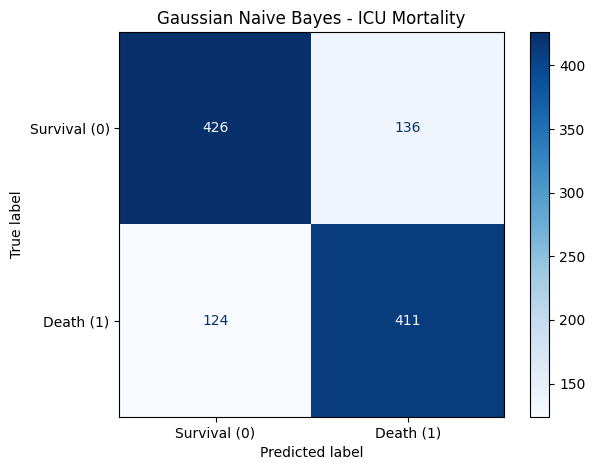

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Survival (0)", "Death (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Gaussian Naive Bayes - ICU Mortality")
plt.tight_layout()
plt.show()

In [64]:
# Combine training features and labels
train_df = X_train.copy()
train_df["hospital_death"] = y_train.values

# Calculate correlation between each feature and mortality
correlations = (
    train_df.corr(numeric_only=True)["hospital_death"]
    .drop("hospital_death")
)

# Top 10 features positively correlated with death
top_positive = correlations.sort_values(ascending=False).head(10)

# Top 10 features negatively correlated with death
top_negative = correlations.sort_values().head(10)

print("Top 10 features positively correlated with death:")
print(top_positive)

print("\nTop 10 features negatively correlated with death:")
print(top_negative)

# Top 10 strongest correlations, regardless of direction
top_10_absolute = correlations.abs().sort_values(
    ascending=False
).head(10)

print("\nTop 10 strongest correlations (absolute value):")
print(pd.DataFrame({
    "Correlation": correlations[top_10_absolute.index],
    "Absolute correlation": top_10_absolute
}))


Top 10 features positively correlated with death:
apache_4a_icu_death_prob    0.454444
ventilated_apache           0.389998
intubated_apache            0.289391
bun_apache                  0.288546
d1_heartrate_max            0.242090
creatinine_apache           0.210906
wbc_apache                  0.207755
h1_resprate_max             0.189071
heart_rate_apache           0.183132
d1_potassium_max            0.179160
Name: hospital_death, dtype: float64

Top 10 features negatively correlated with death:
gcs_verbal_apache   -0.377850
gcs_eyes_apache     -0.367440
gcs_motor_apache    -0.360363
d1_sysbp_min        -0.324410
d1_mbp_min          -0.308595
d1_diasbp_min       -0.277641
d1_temp_min         -0.268836
d1_hco3_min         -0.256986
d1_spo2_min         -0.244576
h1_mbp_min          -0.226764
Name: hospital_death, dtype: float64

Top 10 strongest correlations (absolute value):
                          Correlation  Absolute correlation
apache_4a_icu_death_prob     0.454444         

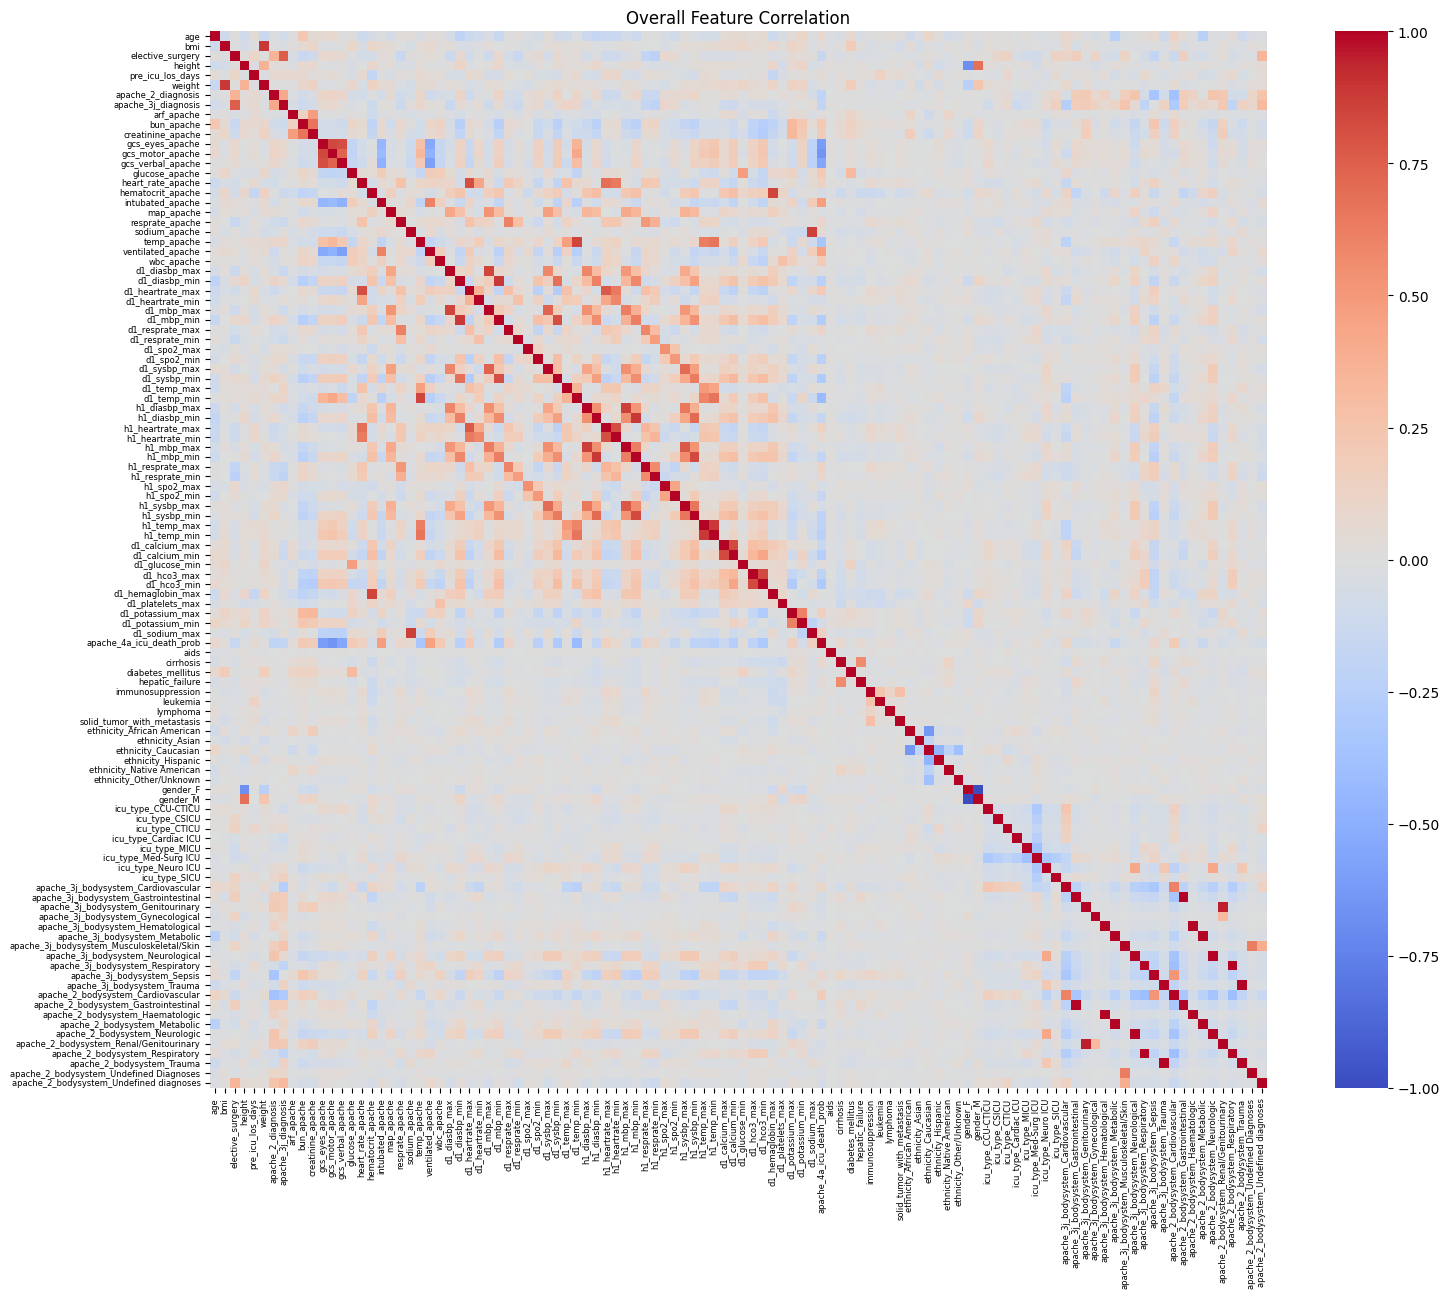

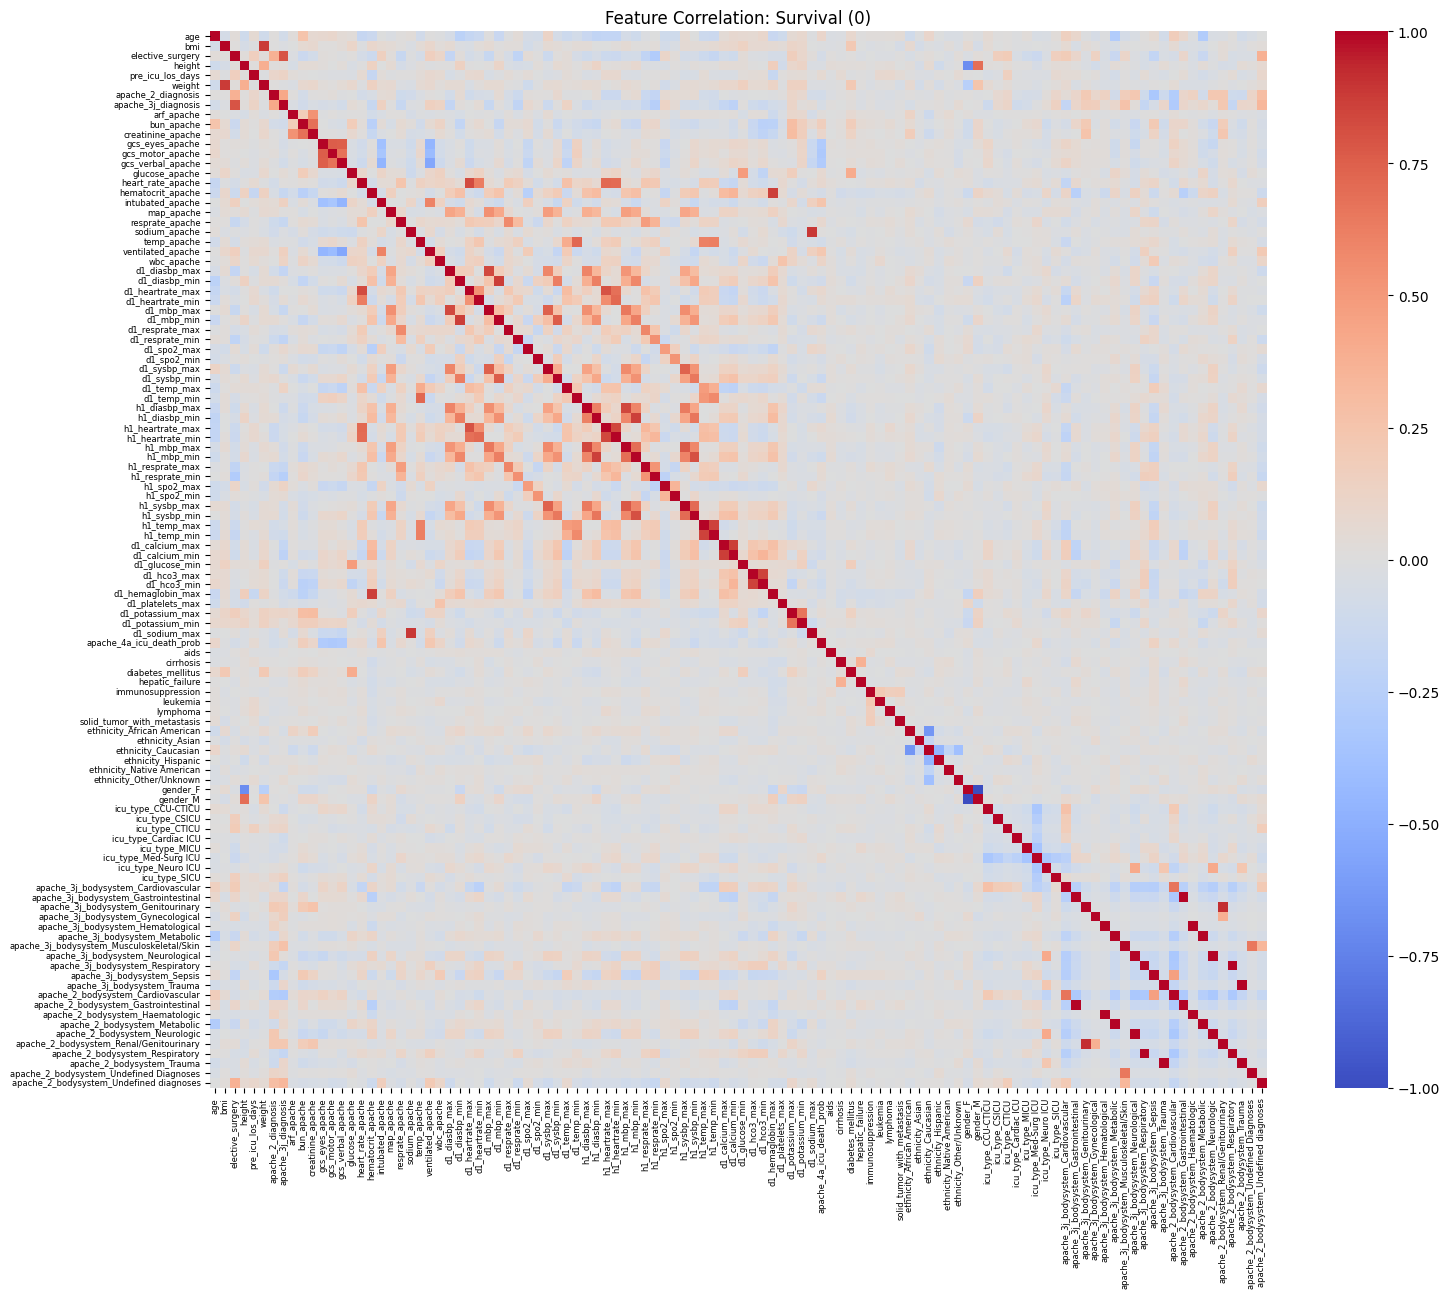

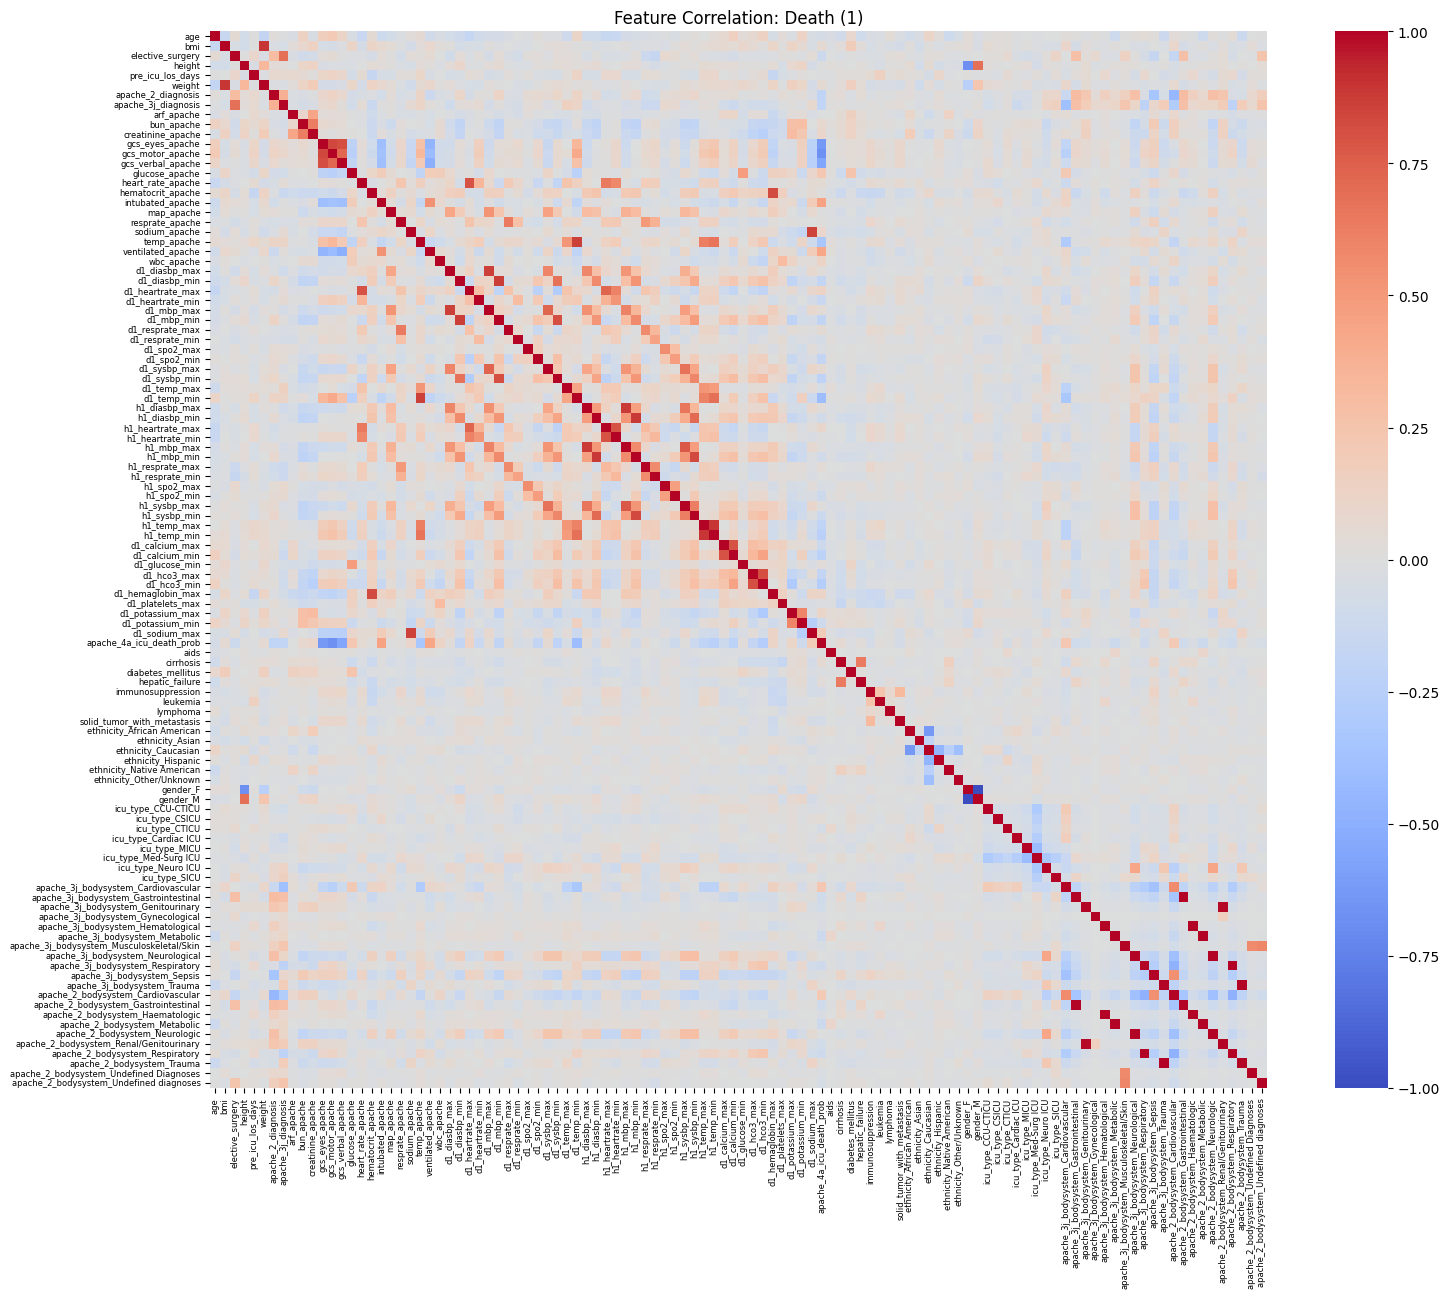

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Combine training features and labels
train_df = X_train.copy()
train_df["hospital_death"] = np.asarray(y_train).ravel()

# Select the 108 numerical features
feature_cols = X_train.columns

# Separate patients by outcome
survival_df = train_df[train_df["hospital_death"] == 0]
death_df = train_df[train_df["hospital_death"] == 1]

# Calculate Pearson correlation matrices
corr_overall = train_df[feature_cols].corr(method="pearson")
corr_survival = survival_df[feature_cols].corr(method="pearson")
corr_death = death_df[feature_cols].corr(method="pearson")

# Plot the three heatmaps
correlation_matrices = [
    (corr_overall, "Overall Feature Correlation"),
    (corr_survival, "Feature Correlation: Survival (0)"),
    (corr_death, "Feature Correlation: Death (1)")
]

for corr, title in correlation_matrices:
    plt.figure(figsize=(16, 13))

    sns.heatmap(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        xticklabels=True,
        yticklabels=True,
        square=True
    )

    plt.title(title)
    plt.xticks(rotation=90, fontsize=6)
    plt.yticks(rotation=0, fontsize=6)
    plt.tight_layout()
    plt.show()


In [73]:
# Extract unique feature pairs from a correlation matrix
def get_high_correlations(corr, threshold=0.7):
    upper_triangle = corr.where(
        np.triu(np.ones(corr.shape), k=1).astype(bool)
    )

    pairs = (
        upper_triangle.stack()
        .rename("correlation")
        .reset_index()
    )

    pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

    pairs = pairs[
        pairs["Correlation"].abs() >= threshold
    ]

    return pairs.reindex(
        pairs["Correlation"].abs().sort_values(
            ascending=False
        ).index
    ).reset_index(drop=True)


print("Highly correlated pairs: overall")
print(get_high_correlations(corr_overall).to_string(index=False))

print("\nHighly correlated pairs: survival")
print(get_high_correlations(corr_survival).to_string(index=False))

print("\nHighly correlated pairs: death")
print(get_high_correlations(corr_death).to_string(index=False))


Highly correlated pairs: overall
                            Feature 1                               Feature 2  Correlation
          apache_3j_bodysystem_Trauma              apache_2_bodysystem_Trauma     1.000000
     apache_3j_bodysystem_Respiratory         apache_2_bodysystem_Respiratory     1.000000
    apache_3j_bodysystem_Neurological          apache_2_bodysystem_Neurologic     1.000000
       apache_3j_bodysystem_Metabolic           apache_2_bodysystem_Metabolic     1.000000
   apache_3j_bodysystem_Hematological        apache_2_bodysystem_Haematologic     1.000000
apache_3j_bodysystem_Gastrointestinal    apache_2_bodysystem_Gastrointestinal     1.000000
                             gender_F                                gender_M    -1.000000
   apache_3j_bodysystem_Genitourinary apache_2_bodysystem_Renal/Genitourinary     0.946142
                                  bmi                                  weight     0.889525
                          h1_temp_max                    